In [2]:
%pip install pandas numpy matplotlib 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import matplotlib.gridspec as GridSpec 

In [4]:
#loading and visualizing dataframe
df = pd.read_excel("monitoreo_nutrivec.xlsx")

df.head(10)



,FECHA,REPETICIÓN,TRATAMIENTO,OXIGENO (am),pH (am),TEMPERATURA (am),OXIGENO (pm),pH (pm),TEMPERATURA (pm),OXIGENO FINAL,...,TEMPERATURA FINAL,OBSERVACIONES,Unnamed: 13,FECHA .1,BLOQUE,HORA,AMONIO,NITRITO,NITRATO,Unnamed: 20
0,2025-06-19 00:00:00,1.0,1.0,NaN,NaN,NaN,7.0,7.4,27.3,7.0,...,27.3,NaN,NaN,2025-06-19,1.0,NaN,NaN,NaN,NaN,Realizar por bloque
1,2025-06-19 00:00:00,2.0,1.0,NaN,NaN,NaN,7.0,7.4,27.3,7.0,...,27.3,NaN,NaN,2025-06-19,2.0,NaN,NaN,NaN,NaN,NaN
2,2025-06-19 00:00:00,3.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,2025-06-19,3.0,NaN,NaN,NaN,NaN,NaN
3,2025-06-19 00:00:00,1.0,2.0,NaN,NaN,NaN,8.9,7.3,27.4,8.9,...,27.4,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
4,2025-06-19 00:00:00,2.0,2.0,NaN,NaN,NaN,8.9,7.3,27.4,8.9,...,27.4,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
5,2025-06-19 00:00:00,3.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
6,2025-06-19 00:00:00,1.0,3.0,NaN,NaN,NaN,8.5,7.2,27.3,8.5,...,27.3,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
7,2025-06-19 00:00:00,2.0,3.0,NaN,NaN,NaN,8.5,7.2,27.3,8.5,...,27.3,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
8,2025-06-19 00:00:00,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
9,2025-06-19 00:00:00,1.0,4.0,NaN,NaN,NaN,8.3,7.1,27.2,8.3,...,27.2,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
#exploring dataframe shape
df.shape

(1046386, 21)

In [6]:
#counting and removing na values 

df.isna().sum()

FECHA                  1045653
REPETICIÓN             1045654
TRATAMIENTO            1045654
OXIGENO (am)           1045730
pH (am)                1045718
TEMPERATURA (am)       1045718
OXIGENO (pm)           1045730
pH (pm)                1045718
TEMPERATURA (pm)       1045727
OXIGENO FINAL          1045898
pH FINAL               1045886
TEMPERATURA  FINAL     1045886
OBSERVACIONES          1046302
Unnamed: 13            1046386
FECHA .1               1046383
BLOQUE                 1046383
HORA                   1046386
AMONIO                 1046386
NITRITO                1046386
NITRATO                1046386
Unnamed: 20            1046385
dtype: int64

In [7]:
df_cleaned = df.loc[:, ["FECHA ", "REPETICIÓN", "TRATAMIENTO", "OXIGENO (am)", "pH (am)", "TEMPERATURA (am) ", "OXIGENO (pm) ", "pH (pm)", "TEMPERATURA (pm)", "OXIGENO FINAL ", "pH FINAL ", "TEMPERATURA  FINAL "]]

df_cleaned.head(10)

df = df_cleaned.dropna()
df

,FECHA,REPETICIÓN,TRATAMIENTO,OXIGENO (am),pH (am),TEMPERATURA (am),OXIGENO (pm),pH (pm),TEMPERATURA (pm),OXIGENO FINAL,pH FINAL,TEMPERATURA FINAL
12,2025-06-20 00:00:00,1.0,1.0,9.0,7.4,25.6,9.3,7.3,26.3,9.15,7.35,25.95
13,2025-06-20 00:00:00,2.0,1.0,9.0,7.4,25.6,9.3,7.3,26.3,9.15,7.35,25.95
15,2025-06-20 00:00:00,1.0,2.0,9.4,7.3,26.6,9.6,7.2,27.1,9.50,7.25,26.85
16,2025-06-20 00:00:00,2.0,2.0,9.4,7.3,26.6,9.6,7.2,27.1,9.50,7.25,26.85
18,2025-06-20 00:00:00,1.0,3.0,8.9,7.2,26.6,7.8,7.1,27.4,8.35,7.15,27.00
...,...,...,...,...,...,...,...,...,...,...,...,...
499,2025-07-30 00:00:00,2.0,3.0,6.8,7.0,27.0,7.0,7.1,27.5,6.90,7.05,27.25
500,2025-07-30 00:00:00,3.0,3.0,6.8,7.0,27.0,7.0,7.1,27.5,6.90,7.05,27.25
501,2025-07-30 00:00:00,1.0,4.0,7.4,6.9,26.6,7.4,7.0,27.1,7.40,6.95,26.85
502,2025-07-30 00:00:00,2.0,4.0,6.4,7.0,26.7,7.1,7.0,27.2,6.75,7.00,26.95


In [8]:
df_control = df[df["TRATAMIENTO"] == 1.0]
df_g1 = df[df["TRATAMIENTO"] == 2.0]
df_g2  = df[df["TRATAMIENTO"] == 3.0]
df_g3 = df[df["TRATAMIENTO"] == 4.0]



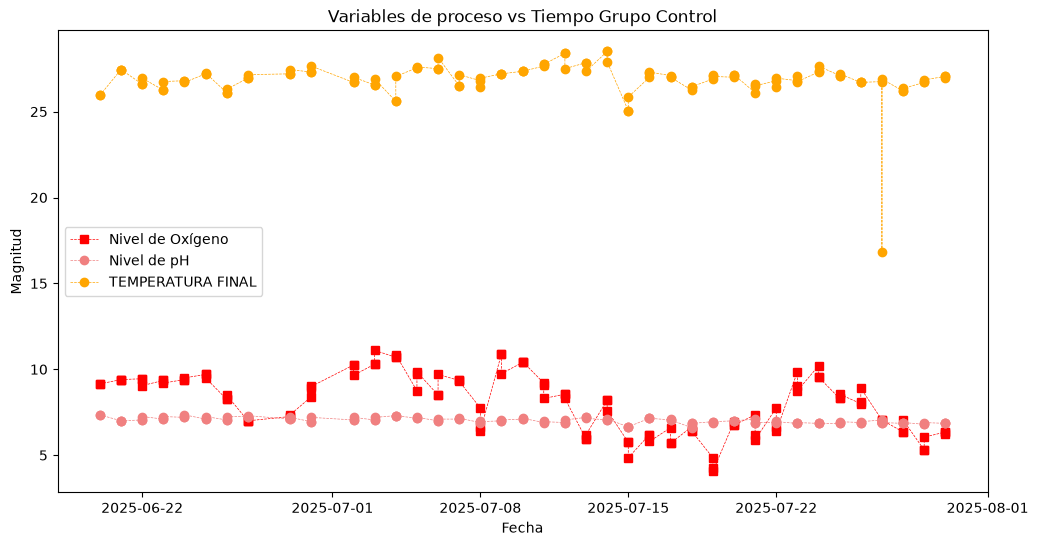

In [9]:
#visualization 

plt.figure(figsize=(12, 6))

plt.plot(df_control["FECHA "], df_control["OXIGENO FINAL "], marker="s", color="red", linestyle="--", linewidth=0.5, label="Nivel de Oxígeno")
plt.plot(df_control["FECHA "], df_control["pH FINAL "], marker="o", color="lightcoral", linestyle="--", linewidth=0.5, label="Nivel de pH")
plt.plot(df_control["FECHA "], df_control["TEMPERATURA  FINAL "], marker="o", color="orange", linestyle="--", linewidth=0.5, label="TEMPERATURA FINAL")
plt.title("Variables de proceso vs Tiempo Grupo Control")
plt.xlabel("Fecha")
plt.ylabel("Magnitud")

plt.legend()
plt.show()

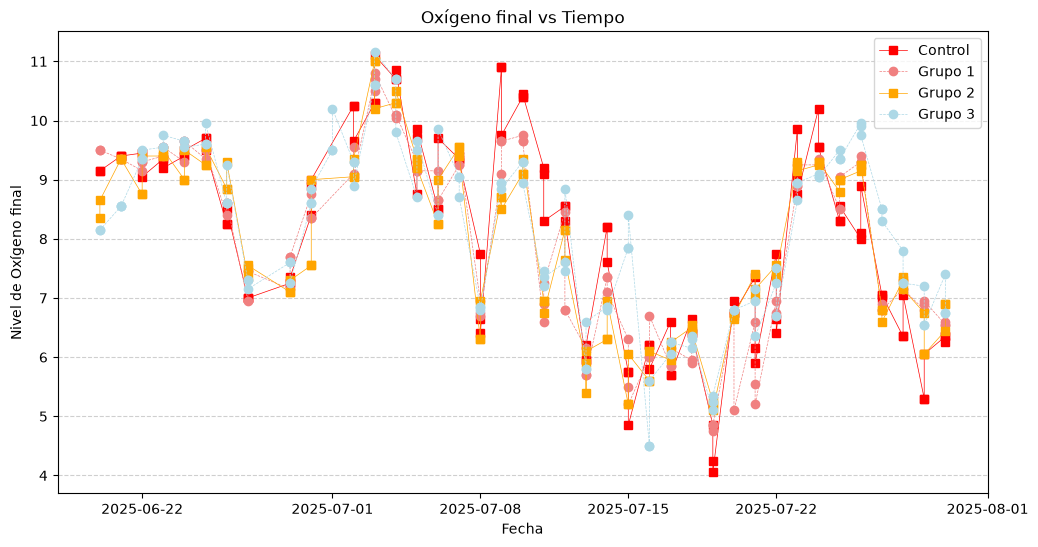

In [15]:
#visualization 

plt.figure(figsize=(12, 6))

plt.plot(df_control["FECHA "], df_control["OXIGENO FINAL "], marker="s", color="red", linestyle="-", linewidth=0.5, label="Control")
plt.plot(df_g1["FECHA "], df_g1["OXIGENO FINAL "], marker="o", color="lightcoral", linestyle="--", linewidth=0.5, label="Grupo 1")
plt.plot(df_g2["FECHA "], df_g2["OXIGENO FINAL "], marker="s", color="orange", linestyle="-", linewidth=0.5, label="Grupo 2")
plt.plot(df_g3["FECHA "], df_g3["OXIGENO FINAL "], marker="o", color="lightblue", linestyle="--", linewidth=0.5, label="Grupo 3")
plt.title("Oxígeno final vs Tiempo")
plt.xlabel("Fecha")
plt.ylabel("Nivel de Oxígeno final")

plt.grid(True, axis="y", linestyle= "--", alpha=0.6, zorder=0)

plt.legend()
plt.show()

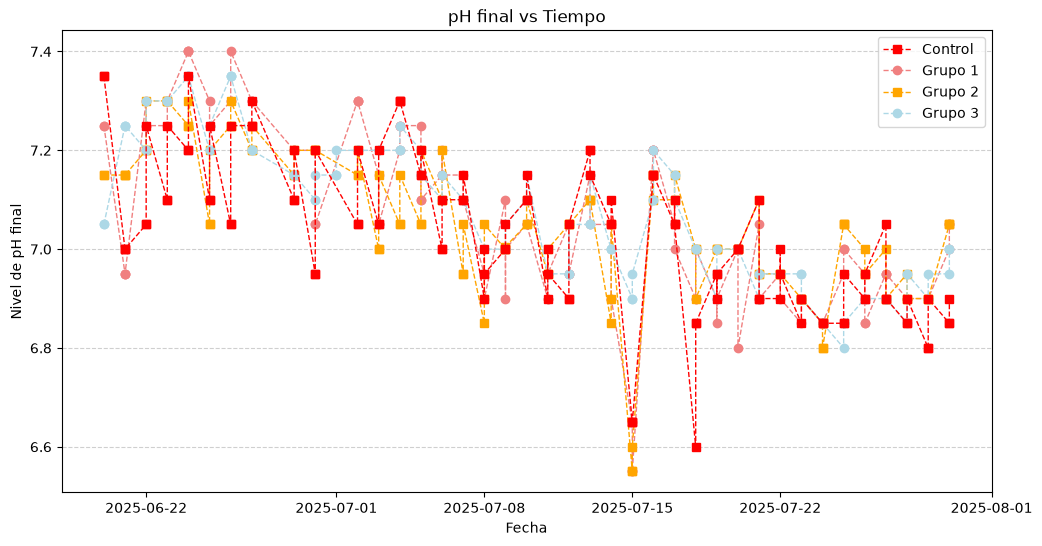

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(df_control["FECHA "], df_control["pH FINAL "], marker="s", color="red", linestyle="--", linewidth=1, label="Control", zorder=3)
plt.plot(df_g1["FECHA "], df_g1["pH FINAL "], marker="o", color="lightcoral", linestyle="--", linewidth=1, label="Grupo 1")
plt.plot(df_g2["FECHA "], df_g2["pH FINAL "], marker="s", color="orange", linestyle="--", linewidth=1, label="Grupo 2")
plt.plot(df_g3["FECHA "], df_g3["pH FINAL "], marker="o", color="lightblue", linestyle="--", linewidth=1, label="Grupo 3")
plt.title("pH final vs Tiempo")
plt.xlabel("Fecha")
plt.ylabel("Nivel de pH final")

plt.grid(True, axis="y", linestyle= "--", alpha=0.6, zorder=0)

plt.legend()
plt.show()

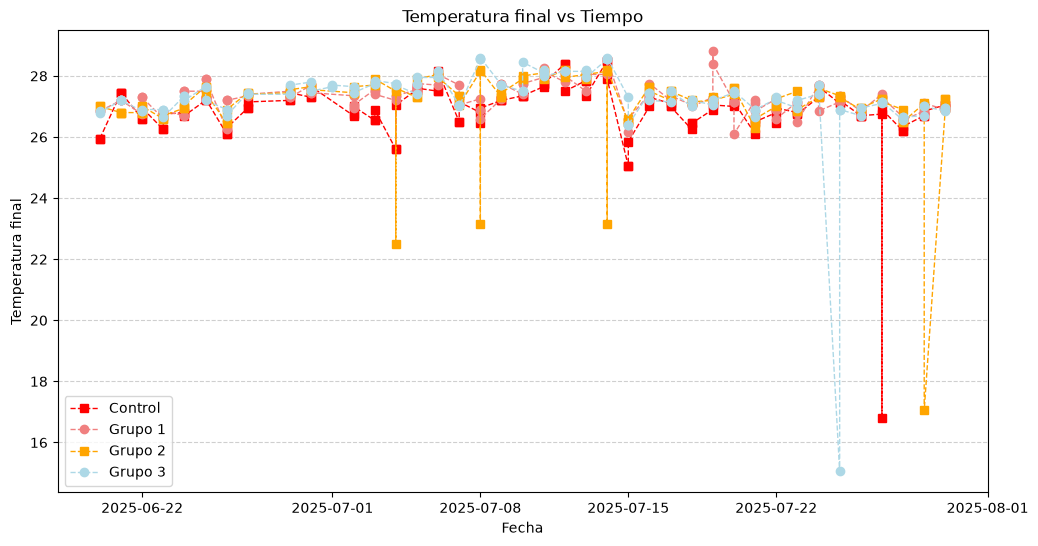

In [16]:
plt.figure(figsize=(12, 6))

plt.plot(df_control["FECHA "], df_control["TEMPERATURA  FINAL "], marker="s", color="red", linestyle="--", linewidth=1, label="Control")
plt.plot(df_g1["FECHA "], df_g1["TEMPERATURA  FINAL "], marker="o", color="lightcoral", linestyle="--", linewidth=1, label="Grupo 1")
plt.plot(df_g2["FECHA "], df_g2["TEMPERATURA  FINAL "], marker="s", color="orange", linestyle="--", linewidth=1, label="Grupo 2")
plt.plot(df_g3["FECHA "], df_g3["TEMPERATURA  FINAL "], marker="o", color="lightblue", linestyle="--", linewidth=1, label="Grupo 3")
plt.title("Temperatura final vs Tiempo")
plt.xlabel("Fecha")
plt.ylabel("Temperatura final")
plt.grid(True, axis="y", linestyle= "--", alpha=0.6, zorder=0)

plt.legend()
plt.show()